In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import glob
import numpy as np
import re
import unicodedata

folder_path = "Spreadsheets from JCR"
all_dfs = []
for file in os.listdir(folder_path):
    if "LeslieHNicoll" in file and file.endswith(".xlsx"):
        file_path = os.path.join(folder_path, file)
        match = re.search(r"(19|20)\d{2}", file)
        if not match:
            continue        
        year = int(match.group())
        raw = pd.read_excel(file_path, header=None)
        header_row = raw[
            raw.apply(lambda r: r.astype(str)
                      .str.contains("Journal name", na=False)
                      .any(), axis=1)
        ].index
        if len(header_row) == 0:
            continue
        header_row = header_row[0]
        df = pd.read_excel(file_path, header=header_row)
        # remove footer rows
        df = df[~df.iloc[:, 0].astype(str).str.contains("Copyright|Terms of Use", na=False)]
        df.columns = df.columns.str.strip()
        # standardize journal column
        df.rename(columns={"Journal name": "Journal_name"}, inplace=True)
        # add year
        df["Year"] = year
        jif_col = [c for c in df.columns if "JIF" in c and "Quartile" not in c]
        jci_col = [c for c in df.columns if "JCI" in c]
        if len(jif_col) == 1:
            df.rename(columns={jif_col[0]: "JIF"}, inplace=True)
        if len(jci_col) == 1:
            df.rename(columns={jci_col[0]: "JCI"}, inplace=True)
        all_dfs.append(df)
final_df = pd.concat(all_dfs, ignore_index=True, sort=False)
final_df = final_df.dropna(how="all")
final_df = final_df.drop_duplicates(subset=["Journal_name", "Year"])
final_df["JIF"] = pd.to_numeric(final_df.get("JIF"), errors="coerce")
final_df["JCI"] = pd.to_numeric(final_df.get("JCI"), errors="coerce")
final_df["Total Citations"] = pd.to_numeric(final_df.get("Total Citations"), errors="coerce")
final_df = final_df.sort_values(["Journal_name", "Year"]).reset_index(drop=True)
final_df = final_df.dropna(subset=["Journal_name"])
final_df["Journal_name"] = (
    final_df["Journal_name"]
    .astype(str)
    .apply(lambda x: unicodedata.normalize("NFKC", x))
    .str.strip()
    .str.upper())
final_df
df = final_df
df.head(3)

C:\Users\mmquazi\AppData\Local\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


,Journal_name,JCR Abbreviation,Publisher,ISSN,eISSN,Category,Edition,Total Citations,JIF,JIF Quartile,JCI,% of Citable OA,Year
0,AACN ADVANCED CRITICAL CARE,AACN ADV CRIT CARE,AMER ASSOC CRITICAL CARE NURSES,1559-7768,1559-7776,NURSING,ESCI,594.0,NaN,NaN,0.54,0.00%,2020
1,AACN ADVANCED CRITICAL CARE,AACN ADV CRIT CARE,AMER ASSOC CRITICAL CARE NURSES,1559-7768,1559-7776,NURSING,ESCI,747.0,NaN,NaN,0.55,0.00%,2021
2,AACN ADVANCED CRITICAL CARE,AACN ADV CRIT CARE,AMER ASSOC CRITICAL CARE NURSES,1559-7768,1559-7776,NURSING,ESCI,710.0,2.2,NaN,0.77,0.00%,2022


In [2]:
def run_jif_stats_epoch(df_input, label, year_min, year_max, journals=None):

    if journals is None:
        journals = df_input['Journal_name'].unique()

    df_subset = df_input[df_input['Journal_name'].isin(journals)].copy()
    df_subset = df_subset.sort_values(['Journal_name', 'Year'])

    df_subset['JIF_prev'] = df_subset.groupby('Journal_name')['JIF'].shift(1)
    df_subset['JIF_pct_change'] = df_subset.groupby('Journal_name')['JIF'].pct_change() * 100

    df_epoch = df_subset[(df_subset['Year'] >= year_min) & (df_subset['Year'] <= year_max)].copy()

    df_valid = df_epoch[
        df_epoch['JIF_prev'].notna() &
        (df_epoch['JIF_prev'] != 0) &
        df_epoch['JIF_pct_change'].notna() &
        np.isfinite(df_epoch['JIF_pct_change'])
    ]['JIF_pct_change']

    n_journals = len(df_epoch['Journal_name'].unique())
    desc = df_valid.describe(percentiles=[.25, .75])

    return {
        'Epoch': label,
        'N journals': n_journals,
        'N observations': len(df_valid),
        'Mean (%)': round(desc['mean'], 1),
        'Median (%)': round(desc['50%'], 1),
        'Std (%)': round(desc['std'], 1),
        'Min (%)': round(desc['min'], 1),
        'Max (%)': round(desc['max'], 1),
        'Q1 (%)': round(desc['25%'], 1),
        'Q3 (%)': round(desc['75%'], 1),
    }
# ── journal set ─────────────────────────────────────────────────────────
journals_all_221  = df['Journal_name'].unique()                                        # all 221

epochs = [
    ('Overall (1997–2024)',  1997, 2024),
    ('Epoch 1 (1997–2004)', 1997, 2004),
    ('Epoch 2 (2005–2018)', 2005, 2018),
    ('Epoch 3 (2019–2024)', 2019, 2024),
]
for name, journal_set in [('ALL 221 journals', journals_all_221)]:
    print(f"\n{'#'*60}")
    print(f"  {name}")
    print(f"{'#'*60}")
    results = [run_jif_stats_epoch(df, label, y_min, y_max, journals=journal_set)
               for label, y_min, y_max in epochs]
    results_df = pd.DataFrame(results).set_index('Epoch').T
    print(results_df.to_string())


############################################################
  ALL 221 journals
############################################################
Epoch           Overall (1997–2024)  Epoch 1 (1997–2004)  Epoch 2 (2005–2018)  Epoch 3 (2019–2024)
N journals                    221.0                 49.0                130.0                199.0
N observations               2004.0                151.0                978.0                875.0
Mean (%)                        9.8                  9.3                  9.7                 10.0
Median (%)                      2.7                  0.0                  2.7                  5.6
Std (%)                        37.0                 46.5                 40.4                 30.7
Min (%)                      -100.0               -100.0               -100.0                -62.5
Max (%)                       548.1                393.3                548.1                300.0
Q1 (%)                         -7.7                  0.0          

C:\Users\mmquazi\AppData\Local\Temp\ipykernel_64404\459893118.py:10: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df_subset['JIF_pct_change'] = df_subset.groupby('Journal_name')['JIF'].pct_change() * 100
C:\Users\mmquazi\AppData\Local\Temp\ipykernel_64404\459893118.py:10: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df_subset['JIF_pct_change'] = df_subset.groupby('Journal_name')['JIF'].pct_change() * 100
C:\Users\mmquazi\AppData\Local\Temp\ipykernel_64404\459893118.py:10: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be remo

C:\Users\mmquazi\AppData\Local\Temp\ipykernel_64404\4264736984.py:9: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df_subset['JIF_pct_change'] = df_subset.groupby('Journal_name')['JIF'].pct_change() * 100
C:\Users\mmquazi\AppData\Local\Temp\ipykernel_64404\4264736984.py:9: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  df_subset['JIF_pct_change'] = df_subset.groupby('Journal_name')['JIF'].pct_change() * 100
C:\Users\mmquazi\AppData\Local\Temp\ipykernel_64404\4264736984.py:9: FutureWarning: The default fill_method='ffill' in SeriesGroupBy.pct_change is deprecated and will be remo

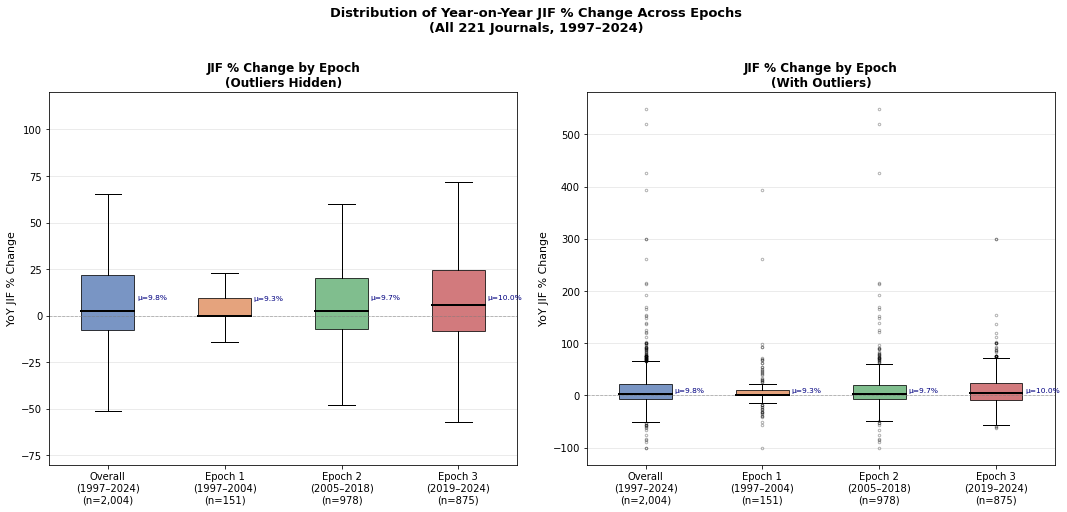

In [3]:
def get_epoch_data(df_input, year_min, year_max, journals=None):
    """Return clean JIF pct change values for a given epoch."""
    if journals is None:
        journals = df_input['Journal_name'].unique()

    df_subset = df_input[df_input['Journal_name'].isin(journals)].copy()
    df_subset = df_subset.sort_values(['Journal_name', 'Year'])
    df_subset['JIF_prev'] = df_subset.groupby('Journal_name')['JIF'].shift(1)
    df_subset['JIF_pct_change'] = df_subset.groupby('Journal_name')['JIF'].pct_change() * 100

    df_epoch = df_subset[(df_subset['Year'] >= year_min) & (df_subset['Year'] <= year_max)].copy()

    df_valid = df_epoch[
        df_epoch['JIF_prev'].notna() &
        (df_epoch['JIF_prev'] != 0) &
        df_epoch['JIF_pct_change'].notna() &
        np.isfinite(df_epoch['JIF_pct_change'])
    ]['JIF_pct_change']

    return df_valid.values
journals_all = df['Journal_name'].unique()

epochs = [
    ('Overall\n(1997–2024)',  1997, 2024),
    ('Epoch 1\n(1997–2004)', 1997, 2004),
    ('Epoch 2\n(2005–2018)', 2005, 2018),
    ('Epoch 3\n(2019–2024)', 2019, 2024),
]

data   = [get_epoch_data(df, y_min, y_max, journals_all) for _, y_min, y_max in epochs]
labels = [e[0] for e in epochs]
ns     = [len(d) for d in data]
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

# ── Summary stats for annotation ────────────────────────────────────────────
means   = [9.8,  9.3, 9.7,  10.0]
medians = [2.7,  0.0,  2.7,  5.6]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

for ax, show_fliers, suffix in zip(axes, [False, True], ['Outliers Hidden', 'With Outliers']):
    bp = ax.boxplot(data, patch_artist=True, showfliers=show_fliers,
                    flierprops=dict(marker='o', markersize=2.5, alpha=0.3),
                    medianprops=dict(color='black', linewidth=2))

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    for i, (mean, median) in enumerate(zip(means, medians), start=1):
        ax.annotate(f'μ={mean}%', xy=(i, mean), xytext=(i + 0.25, mean),
                    fontsize=7.5, color='navy', va='center')

    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.6)
    ax.set_xticks(range(1, len(labels) + 1))
    ax.set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(labels, ns)], fontsize=10)
    ax.set_ylabel('YoY JIF % Change', fontsize=11)
    ax.set_title(f'JIF % Change by Epoch\n({suffix})', fontsize=12, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

    if not show_fliers:
        ax.set_ylim(-80, 120) 
plt.suptitle('Distribution of Year-on-Year JIF % Change Across Epochs\n(All 221 Journals, 1997–2024)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
#plt.savefig('results/figure3.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
df_all = df.copy()

# ── Sum total citations across ALL years per journal ─────────────────────────
top_citations = (
    df_all.groupby('Journal_name')['Total Citations']
    .sum()
    .reset_index()
    .sort_values('Total Citations', ascending=False)
)

top_citations = top_citations[top_citations['Total Citations'].notna()]

total_citations = top_citations['Total Citations'].sum()
n = len(top_citations)
print(f"Journals analysed: {n}")
print(f"Total citations:   {total_citations:,.0f}\n")

# ── Concentration by top % ───────────────────────────────────────────────────
for pct, label in [(0.10, 'Top 10%'), (0.25, 'Top 25%'), (0.50, 'Top 50%')]:
    k = max(1, int(np.ceil(n * pct)))
    top_cites = top_citations.head(k)['Total Citations'].sum()
    share = top_cites / total_citations * 100
    print(f"{label:>8}  ({k:>3} journals)  →  {share:.1f}% of total citations  ({top_cites:,.0f})")

# ── Gini coefficient ─────────────────────────────────────────────────────────
def gini(values):
    arr = np.sort(np.array(values, dtype=float))
    n = len(arr)
    index = np.arange(1, n + 1)
    return (2 * np.sum(index * arr) - (n + 1) * np.sum(arr)) / (n * np.sum(arr))

g = gini(top_citations['Total Citations'])
print(f"\nGini coefficient:  {g:.4f}  (0 = perfect equality, 1 = total concentration)")

Journals analysed: 221
Total citations:   706,224

 Top 10%  ( 23 journals)  →  29.0% of total citations  (204,751)
 Top 25%  ( 56 journals)  →  55.9% of total citations  (394,719)
 Top 50%  (111 journals)  →  85.8% of total citations  (606,243)

Gini coefficient:  0.4824  (0 = perfect equality, 1 = total concentration)
